In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report, roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve
)

In [10]:
df = pd.read_csv('DiaBD.csv')

In [11]:
print(df.shape)

(5288, 15)


In [12]:
df.head(10)

,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,height,weight,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic
0,42,Female,66,110,73,5.88,1.65,70.2,25.75,0,0,0,0,0,No
1,35,Female,60,125,68,5.71,1.47,42.5,19.58,0,0,0,0,0,No
2,62,Female,57,127,74,6.85,1.52,47.0,20.24,0,0,0,0,0,No
3,73,Male,55,193,112,6.28,1.63,57.4,21.72,0,0,0,0,0,No
4,68,Female,71,150,81,5.71,1.42,36.0,17.79,0,0,0,0,0,No
5,40,Male,48,131,73,7.22,1.63,61.9,23.42,0,0,0,0,0,No
6,35,Female,66,123,72,5.40,1.42,42.3,20.91,0,0,0,0,0,No
7,25,Female,84,152,90,7.20,1.52,57.7,24.84,0,0,0,0,0,No
8,50,Male,80,135,87,17.04,1.68,67.8,24.13,0,0,0,0,0,Yes
9,70,Male,64,129,75,8.04,1.65,56.0,20.54,0,0,0,0,0,No


In [5]:
print("Missing Values:\n", df.isnull().sum())

Missing Values:
 age                       0
gender                    0
pulse_rate                0
systolic_bp               0
diastolic_bp              0
glucose                   0
height                    0
weight                    0
bmi                       0
family_diabetes           0
hypertensive              0
family_hypertension       0
cardiovascular_disease    0
stroke                    0
diabetic                  0
dtype: int64


In [7]:
df_clean = df[
    (df['glucose'] > 0) &
    (df['pulse_rate'] >= 40) &
    (df['height'] >= 1.0) &
    (df['weight'] >= 25) &
    (df['bmi'].between(12, 60))
].copy()
df_clean['diabetic_num'] = (df_clean['diabetic'] == 'Yes').astype(int)
df_clean['gender_num'] = (df_clean['gender'] == 'Male').astype(int)
print(f"Cleaned Dataset Shape: {df_clean.shape} (Removed {len(df) - len(df_clean)} outlier rows)\n")

Cleaned Dataset Shape: (5274, 17) (Removed 14 outlier rows)



In [8]:
df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=[20, 30, 40, 50, 60, 85],
    labels=['21-30', '31-40', '41-50', '51-60', '61+']
)

cohort_summary = df_clean.groupby('age_group', observed=False).agg(
    patients=('diabetic_num', 'count'),
    diabetes_rate_pct=('diabetic_num', lambda x: round(x.mean() * 100, 2)),
    hypertension_pct=('hypertensive', lambda x: round(x.mean() * 100, 2)),
    mean_glucose=('glucose', lambda x: round(x.mean(), 2)),
    mean_systolic_bp=('systolic_bp', lambda x: round(x.mean(), 1))
)
print("=== AGE-STRATIFIED COHORT SUMMARY ===")
print(cohort_summary, "\n")

=== AGE-STRATIFIED COHORT SUMMARY ===
           patients  diabetes_rate_pct  hypertension_pct  mean_glucose  \
age_group                                                                
21-30           816               2.08              1.10          6.99   
31-40          1503               4.59              5.06          7.43   
41-50          1203               7.32             12.88          7.66   
51-60          1022              10.27             18.30          7.80   
61+             730               8.63             21.78          7.96   

           mean_systolic_bp  
age_group                    
21-30                 123.8  
31-40                 127.8  
41-50                 134.3  
51-60                 141.2  
61+                   147.4   



In [21]:
df_clean["bmi_reported"] = df_clean["bmi"]
df_clean["bmi"] = (df_clean.weight / df_clean.height ** 2).round(2)
df_clean["bmi_cat"] = pd.cut(df_clean.bmi, [0, 18.5, 23, 27.5, np.inf], right=False, labels=["Underweight", "Normal", "Overweight", "High risk"])

# Displaying the outputs
print("=== Distribution of New BMI Categories ===")
print(df_clean["bmi_cat"].value_counts(dropna=False))

print("\n=== Sample of Calculated Values ===")
df_clean[["weight", "height", "bmi_reported", "bmi", "bmi_cat"]].head()

=== Distribution of New BMI Categories ===
bmi_cat
Normal         2499
Overweight     1460
Underweight     794
High risk       521
Name: count, dtype: int64

=== Sample of Calculated Values ===


,weight,height,bmi_reported,bmi,bmi_cat
0,70.2,1.65,25.79,25.79,Overweight
1,42.5,1.47,19.67,19.67,Normal
2,47.0,1.52,20.34,20.34,Normal
3,57.4,1.63,21.60,21.60,Normal
4,36.0,1.42,17.85,17.85,Underweight


In [22]:
df_clean['metabolic_group'] = np.where(
    df_clean['diabetic'] == 'Yes', 'Confirmed Diabetic (Yes)',
    np.where(df_clean['glucose'] >= 11.1, 'Undiagnosed Hyperglycemic (No, Gluc>=11.1)',
             'Non-Diabetic (No, Gluc<11.1)')
)

print("=== Q3: HIDDEN HYPERGLYCEMIA METABOLIC PROFILING ===")
q3_profile = df_clean.groupby('metabolic_group')[
    ['age', 'systolic_bp', 'diastolic_bp', 'bmi', 'glucose', 'hypertensive', 'cardiovascular_disease']].mean().round(2)
print(q3_profile, "\n")

=== Q3: HIDDEN HYPERGLYCEMIA METABOLIC PROFILING ===
                                              age  systolic_bp  diastolic_bp  \
metabolic_group                                                                
Confirmed Diabetic (Yes)                    50.35       147.18         89.63   
Non-Diabetic (No, Gluc<11.1)                45.31       132.79         81.53   
Undiagnosed Hyperglycemic (No, Gluc>=11.1)  47.30       138.37         85.22   

                                              bmi  glucose  hypertensive  \
metabolic_group                                                            
Confirmed Diabetic (Yes)                    23.93    10.99          0.54   
Non-Diabetic (No, Gluc<11.1)                22.22     6.91          0.08   
Undiagnosed Hyperglycemic (No, Gluc>=11.1)  23.18    15.32          0.10   

                                            cardiovascular_disease  
metabolic_group                                                     
Confirmed Diabetic (Yes)   

In [23]:
df_clean['combo_status'] = np.where(
    (df_clean['diabetic_num'] == 1) & (df_clean['hypertensive'] == 1), 'Both Diabetic + Hypertensive',
    np.where(df_clean['diabetic_num'] == 1, 'Diabetic Only',
    np.where(df_clean['hypertensive'] == 1, 'Hypertensive Only', 'Neither'))
)

print("=== Q4: DIABETES x HYPERTENSION INTERACTION ON CVD & STROKE ===")
q4_summary = df_clean.groupby('combo_status').agg(
    patients=('diabetic_num', 'count'),
    mean_age=('age', lambda x: round(x.mean(), 1)),
    cvd_rate_pct=('cardiovascular_disease', lambda x: round(x.mean() * 100, 2)),
    stroke_rate_pct=('stroke', lambda x: round(x.mean() * 100, 2))
)
print(q4_summary, "\n")

=== Q4: DIABETES x HYPERTENSION INTERACTION ON CVD & STROKE ===
                              patients  mean_age  cvd_rate_pct  \
combo_status                                                     
Both Diabetic + Hypertensive       184      53.4          7.61   
Diabetic Only                      158      46.8          1.90   
Hypertensive Only                  402      54.5          4.73   
Neither                           4530      44.6          0.53   

                              stroke_rate_pct  
combo_status                                   
Both Diabetic + Hypertensive             2.17  
Diabetic Only                            0.00  
Hypertensive Only                        2.49  
Neither                                  0.13   



In [24]:
features = [
    'age', 'gender_num', 'pulse_rate', 'systolic_bp', 'diastolic_bp',
    'bmi', 'family_diabetes', 'hypertensive', 'family_hypertension',
    'cardiovascular_disease', 'stroke'
]
X = df_clean[features]
y = df_clean['diabetic_num']

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
test_df = df_clean.loc[X_test.index].copy()

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=8, class_weight='balanced', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, max_depth=3, learning_rate=0.05, random_state=42)
}
print("=== Q1: NON-INVASIVE MODEL BENCHMARK (EXCLUDING GLUCOSE) ===")
model_probs = {}
for name, model in models.items():
    if name == 'Logistic Regression':
        model.fit(X_train_sc, y_train)
        probs = model.predict_proba(X_test_sc)[:, 1]
    else:
        model.fit(X_train, y_train)
        probs = model.predict_proba(X_test)[:, 1]
    model_probs[name] = probs
    print(f"{name:22s} | ROC-AUC: {roc_auc_score(y_test, probs):.3f} | PR-AUC: {average_precision_score(y_test, probs):.3f}")

=== Q1: NON-INVASIVE MODEL BENCHMARK (EXCLUDING GLUCOSE) ===
Logistic Regression    | ROC-AUC: 0.769 | PR-AUC: 0.283
Random Forest          | ROC-AUC: 0.755 | PR-AUC: 0.221
Gradient Boosting      | ROC-AUC: 0.763 | PR-AUC: 0.268


In [27]:
print("=== Q6: GENDER SCREENING GAP & CLINICAL PREVALENCE ===")
q6_summary = df_clean.groupby('gender').agg(
    patients=('diabetic_num', 'count'),
    cohort_share_pct=('diabetic_num', lambda x: round(len(x) / len(df_clean) * 100, 2)),
    mean_age=('age', lambda x: round(x.mean(), 1)),
    diabetic_pct=('diabetic_num', lambda x: round(x.mean() * 100, 2)),
    undiag_high_gluc_pct=('glucose', lambda x: round(((x >= 11.1) & (df_clean.loc[x.index, 'diabetic_num'] == 0)).mean() * 100, 2)),
    hypertensive_pct=('hypertensive', lambda x: round(x.mean() * 100, 2))
)
print(q6_summary, "\n")

=== Q6: GENDER SCREENING GAP & CLINICAL PREVALENCE ===
        patients  cohort_share_pct  mean_age  diabetic_pct  \
gender                                                       
Female      3741             70.93      43.9          6.09   
Male        1533             29.07      50.2          7.44   

        undiag_high_gluc_pct  hypertensive_pct  
gender                                          
Female                  4.60             10.83  
Male                    4.63             11.81   



In [30]:
from sklearn.cluster import KMeans

cluster_features = ['age', 'systolic_bp', 'diastolic_bp', 'glucose', 'bmi']
X_clust = StandardScaler().fit_transform(df_clean[cluster_features])
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_clean['risk_cluster'] = kmeans.fit_predict(X_clust)

print("=== UNSUPERVISED K-MEANS RISK PHENOTYPES ===")
print(df_clean.groupby('risk_cluster')[cluster_features + ['diabetic_num', 'hypertensive']].mean().round(2), "\n")

=== UNSUPERVISED K-MEANS RISK PHENOTYPES ===
                age  systolic_bp  diastolic_bp  glucose    bmi  diabetic_num  \
risk_cluster                                                                   
0             46.70       139.00         86.56    17.41  23.66          0.40   
1             52.26       154.85         93.04     7.21  23.38          0.09   
2             41.51       120.30         75.00     6.95  21.63          0.02   

              hypertensive  
risk_cluster                
0                     0.27  
1                     0.23  
2                     0.02   



/tmp/ipykernel_1138/2875126314.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='metabolic_group', y='systolic_bp', ax=axes[0, 1], palette='Set2')
/tmp/ipykernel_1138/2875126314.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(['Non-Diabetic\n(<11.1)', 'Undiagnosed\n(>=11.1)', 'Confirmed\nDiabetic'], fontsize=9)


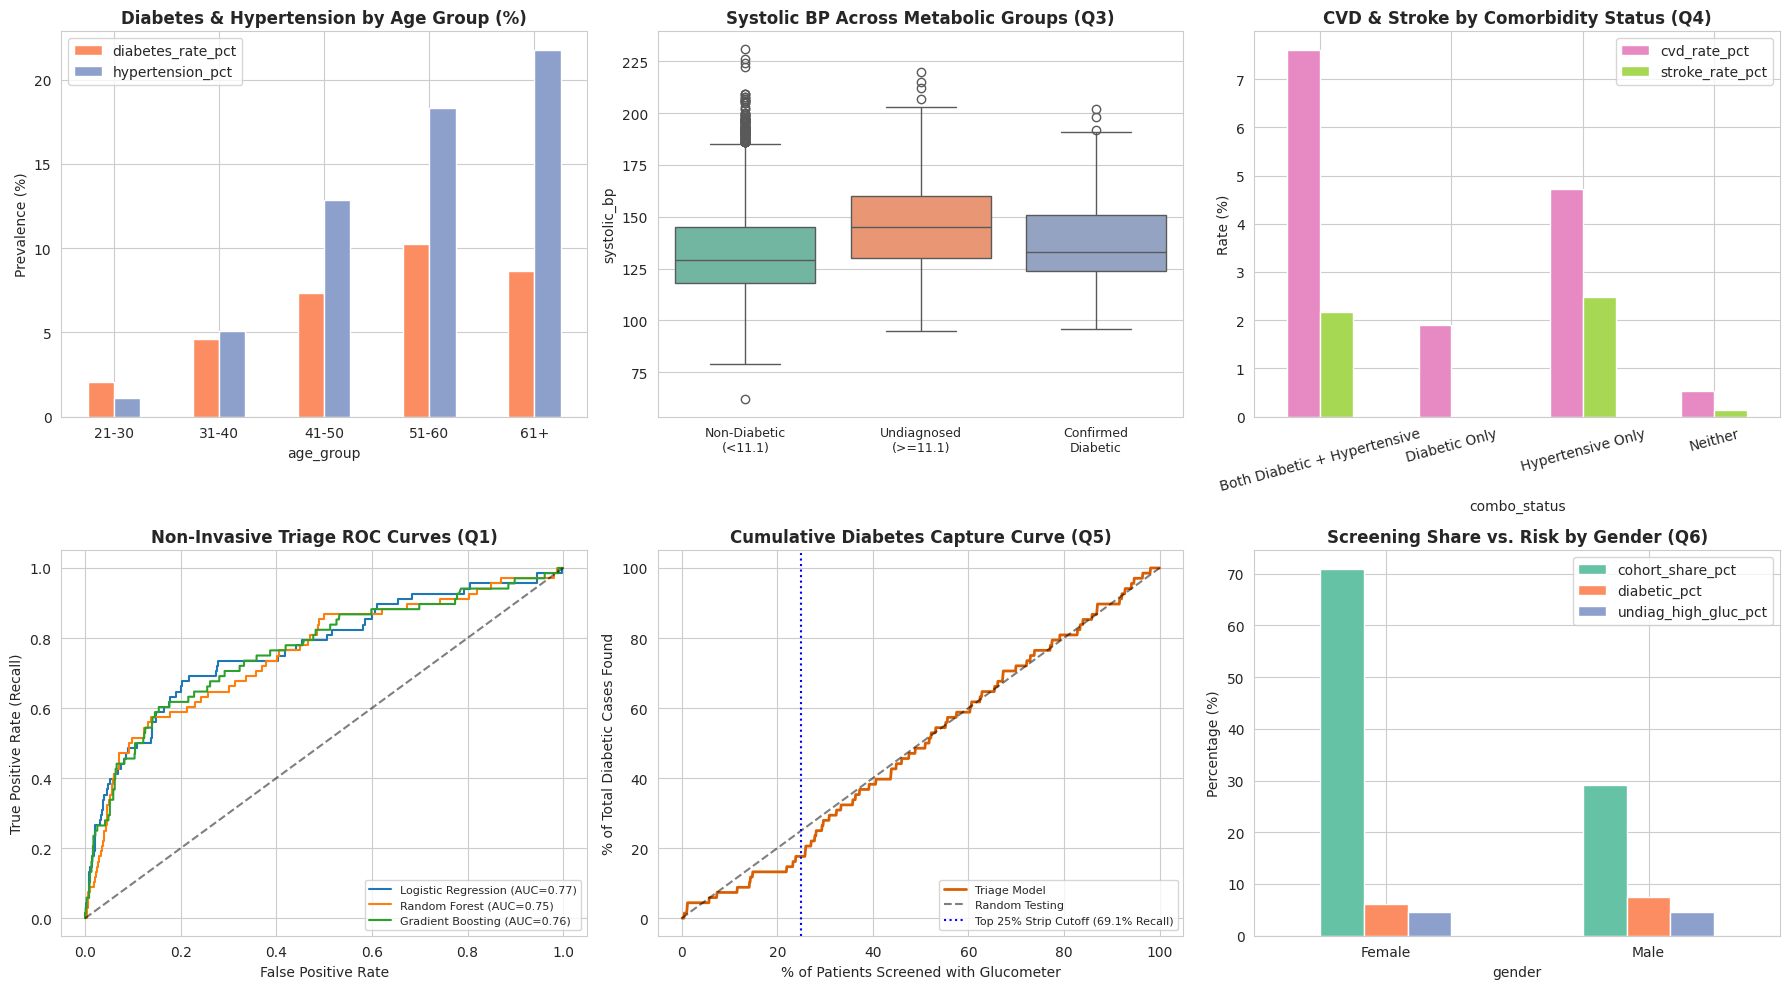

In [34]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
sns.set_style("whitegrid")

cohort_summary[['diabetes_rate_pct', 'hypertension_pct']].plot(kind='bar', ax=axes[0, 0], color=['#fc8d62', '#8da0cb'])
axes[0, 0].set_title('Diabetes & Hypertension by Age Group (%)', fontweight='bold')
axes[0, 0].set_ylabel('Prevalence (%)')
axes[0, 0].tick_params(axis='x', rotation=0)

# Plot 2: Q3 Hidden Hyperglycemia Systolic BP Comparison
sns.boxplot(data=df_clean, x='metabolic_group', y='systolic_bp', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Systolic BP Across Metabolic Groups (Q3)', fontweight='bold')
axes[0, 1].set_xlabel('')
axes[0, 1].set_xticklabels(['Non-Diabetic\n(<11.1)', 'Undiagnosed\n(>=11.1)', 'Confirmed\nDiabetic'], fontsize=9)

# Plot 3: Q4 Comorbidity Interaction on CVD & Stroke
q4_summary[['cvd_rate_pct', 'stroke_rate_pct']].plot(kind='bar', ax=axes[0, 2], color=['#e78ac3', '#a6d854'])
axes[0, 2].set_title('CVD & Stroke by Comorbidity Status (Q4)', fontweight='bold')
axes[0, 2].set_ylabel('Rate (%)')
axes[0, 2].tick_params(axis='x', rotation=15)

# Plot 4: Q1 Non-Invasive ROC Curves
for name, probs in model_probs.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    axes[1, 0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probs):.2f})")
axes[1, 0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1, 0].set_title('Non-Invasive Triage ROC Curves (Q1)', fontweight='bold')
axes[1, 0].set_xlabel('False Positive Rate')
axes[1, 0].set_ylabel('True Positive Rate (Recall)')
axes[1, 0].legend(loc='lower right', fontsize=8)

# Plot 5: Q5 Cumulative Gains / Strip Triage Curve
test_df['cum_patients_pct'] = np.arange(1, len(test_df) + 1) / len(test_df) * 100
test_df['cum_diabetics_pct'] = test_df['diabetic_num'].cumsum() / test_df['diabetic_num'].sum() * 100
axes[1, 1].plot(test_df['cum_patients_pct'], test_df['cum_diabetics_pct'], color='#d95f02', lw=2, label='Triage Model')
axes[1, 1].plot([0, 100], [0, 100], 'k--', alpha=0.5, label='Random Testing')
axes[1, 1].axvline(25, color='blue', linestyle=':', label='Top 25% Strip Cutoff (69.1% Recall)')
axes[1, 1].set_title('Cumulative Diabetes Capture Curve (Q5)', fontweight='bold')
axes[1, 1].set_xlabel('% of Patients Screened with Glucometer')
axes[1, 1].set_ylabel('% of Total Diabetic Cases Found')
axes[1, 1].legend(loc='lower right', fontsize=8)

# Plot 6: Q6 Gender Screening Gap vs Clinical Prevalence
q6_plot = q6_summary[['cohort_share_pct', 'diabetic_pct', 'undiag_high_gluc_pct']]
q6_plot.plot(kind='bar', ax=axes[1, 2], color=['#66c2a5', '#fc8d62', '#8da0cb'])
axes[1, 2].set_title('Screening Share vs. Risk by Gender (Q6)', fontweight='bold')
axes[1, 2].set_ylabel('Percentage (%)')
axes[1, 2].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig('diabd_complete_analysis.png', dpi=150)
plt.show()